# 01. 기온 라벨 만들기 (열섬 강도)
**작성자: A**

결과물: `data_processed/labels.csv` (열: sensor_id, gu, lat, lon, uhi_day, uhi_night)

In [35]:
# ── 공통 설정 (모든 노트북 맨 위에 그대로 두기) ──
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/AICEE_project'   # 모두 같은 경로 (공유 폴더를 '내 드라이브에 바로가기 추가' 해야 함)
DATA = f'{BASE}/data_processed'
RESULTS = f'{BASE}/results'

import sys
sys.path.append(f'{BASE}/shared')
RANDOM_STATE = 42

USE_DUMMY = True   # ← 진짜 데이터 나오면 False로 바꾸기

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1) S-DoT 파일 불러오기
`data_raw/sdot/`에 주간 CSV들과 '설치 위치정보.xlsx'를 넣어두기

In [36]:
import pandas as pd, glob
files = sorted(glob.glob(f'{BASE}/data_raw/sdot/*.csv'))
print(len(files), 'files')
raw = pd.concat([pd.read_csv(f, encoding='cp949') for f in files], ignore_index=True)  # 글자 깨지면 encoding='cp949'
print(raw.columns.tolist()); raw.head()

5 files


/tmp/ipykernel_7706/2739282703.py:4: DtypeWarning: Columns (24,25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.concat([pd.read_csv(f, encoding='cp949') for f in files], ignore_index=True)  # 글자 깨지면 encoding='cp949'
/tmp/ipykernel_7706/2739282703.py:4: DtypeWarning: Columns (25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.concat([pd.read_csv(f, encoding='cp949') for f in files], ignore_index=True)  # 글자 깨지면 encoding='cp949'
/tmp/ipykernel_7706/2739282703.py:4: DtypeWarning: Columns (12,24,25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.concat([pd.read_csv(f, encoding='cp949') for f in files], ignore_index=True)  # 글자 깨지면 encoding='cp949'


['모델명', '시리얼', '센서 시간', '지역구분', '자치구역', '행정구역', '최대 기온', '평균 기온', '최소 기온', '최대 상대습도', '평균 상대습도', '최소 상대습도', '최대 풍속', '평균 풍속', '최소 풍속', '최대 풍향', '평균 풍속.1', '최소 풍속.1', '최대 조도', '평균 조도', '최소 조도', '최대 자외선', '평균 자외선', '최소 자외선', '최대 소음', '평균 소음', '최소 소음', '최대 진동(x)', '평균 진동(x)', '최소 진동(x)', '최대 진동(y)', '평균 진동(y)', '최소 진동(y)', '최대 진동(z)', '평균 진동(z)', '최소 진동(z)', '최대 흑구온도', '평균 흑구온도', '평균 흑구온도.1', '최대 이산화질소', '평균 이산화질소', '최소 이산화질소', '최대 일산화탄소', '평균 일산화탄소', '최소 일산화탄소', '최대 이산화황', '평균 이산화황', '최소 이산화황', '최대 암모니아', '평균 암모니아', '최소 암모니아', '최대 황화수소', '평균 황화수소', '최소 황화수소', '최대 오존', '평균 오존', '최소 오존', '데이터수집시간', '데이터구분번호']


,모델명,시리얼,센서 시간,지역구분,자치구역,행정구역,최대 기온,평균 기온,최소 기온,최대 상대습도,...,평균 암모니아,최소 암모니아,최대 황화수소,평균 황화수소,최소 황화수소,최대 오존,평균 오존,최소 오존,데이터수집시간,데이터구분번호
0,SDOT001,OC3CL200011,2026-08-03_00:07:00,parks,Seoul_Grand_Park,valet_parking1,28.4,28.1,27.7,100.0,...,0.0,0.0,0.011,0.008,0.005,NaN,NaN,NaN,2026-08-03 00:07:15,1
1,SDOT001,OC3CL200012,2026-08-03_00:07:00,traditional_markets,Gwangjin-gu,Hwayang-dong,32.5,32.3,32.2,100.0,...,0.0,0.0,0.000,0.000,0.000,NaN,NaN,NaN,2026-08-03 00:07:15,1
2,SDOT001,OC3CL200013,2026-08-03_00:07:00,main_street,Jongno-gu,Samcheong-dong,29.9,29.7,29.1,100.0,...,0.0,0.0,0.000,0.000,0.000,NaN,NaN,NaN,2026-08-03 00:07:15,1
3,SDOT001,OC3CL200014,2026-08-03_00:07:00,main_street,Jung-gu,Myeong-dong,31.2,31.0,30.8,58.0,...,0.0,0.0,0.000,0.000,0.000,NaN,NaN,NaN,2026-08-03 00:07:15,1
4,SDOT001,OC3CL200015,2026-08-03_00:07:00,roads_and_parks,Gangnam-gu,Sinsa-dong,30.8,30.6,30.5,82.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-08-03 00:07:15,1


## 2) 열 이름 통일
⚠️ 실제 파일의 열 이름을 보고 아래 딕셔너리 왼쪽을 고치기

In [37]:
raw.columns = raw.columns.str.replace(' ', '')

COLMAP = {
    '시리얼': 'sensor_id',
    '센서시간': 'time',
    '평균기온': 'temp',
    '데이터구분번호': 'data_no',
}
d = raw.rename(columns=COLMAP)[['sensor_id', 'time', 'temp', 'data_no']].copy()

# 1) 시간 형식 통일: _HH-MM-SS, _HH:MM:SS 둘 다 → 'YYYY-MM-DD HH:MM:SS', 그다음 정시로
t = d['time'].astype(str).str.replace(r'_(\d{2})-(\d{2})-(\d{2})', r' \1:\2:\3', regex=True).str.replace('_', ' ')
d['time'] = pd.to_datetime(t, errors='coerce').dt.floor('h')
d['temp'] = pd.to_numeric(d['temp'], errors='coerce')
print('시간 변환 실패:', d['time'].isna().sum())

# 2) 같은 센서·같은 시각이면 DATA_NO 2(보정값)만 남기기 — 반드시 시간 정리 '다음'에
n_before = len(d)
d = d.sort_values('data_no').drop_duplicates(['sensor_id', 'time'], keep='last').drop(columns='data_no')
print(f'중복 제거: {n_before - len(d)}행, 남은 행: {len(d)}')

# 팀 공통 규격 기간만: 2026-08-03 00시 ~ 08-30 23시 (센서시간 기준)
d = d[(d['time'] >= '2026-08-03') & (d['time'] < '2026-08-31')]
per_day = d['time'].dt.date.value_counts().sort_index()
print('시각 수:', d['time'].nunique(), '/ 남은 행:', len(d), '/ 센서 수:', d['sensor_id'].nunique())
print('하루 행 수 최소~최대:', per_day.min(), '~', per_day.max())
print(per_day.tail(2))

시간 변환 실패: 0
중복 제거: 0행, 남은 행: 976925
시각 수: 672 / 남은 행: 782791 / 센서 수: 1168
하루 행 수 최소~최대: 27907 ~ 27999
time
2026-08-29    27958
2026-08-30    27946
Name: count, dtype: int64


## 3) EDA 먼저 (2주차: 모델 전에 데이터부터 읽기)
- 분포 히스토그램, 센서별 결측 비율
- **결측이 왜 생겼나?** (2주차 MCAR/MAR/MNAR) 예: 폭염 때 센서가 꺼진다면 '더운 데이터가 빠지는' 편향 → 보고서에 기록

### 기온 요약 통계와 센서별 결측 비율
기온의 평균·범위를 보고, 결측 비율이 높은 센서를 찾는다(기온 결측 약 13.7%)

In [49]:
print(d['temp'].describe())
miss = d.groupby('sensor_id')['temp'].apply(lambda s: s.isna().mean()).sort_values(ascending=False)
print('결측 많은 센서:'); print(miss.head(10))

count    642071.000000
mean         29.610669
std           3.617129
min          15.000000
25%          26.900000
50%          28.918300
75%          32.000000
max          48.600000
Name: temp, dtype: float64
결측 많은 센서:
sensor_id
OC3CL200014    0.0
OC3CL200020    0.0
OC3CL200022    0.0
OC3CL200023    0.0
OC3CL200027    0.0
OC3CL200028    0.0
OC3CL200031    0.0
OC3CL200032    0.0
OC3CL200033    0.0
OC3CL200035    0.0
Name: temp, dtype: float64


### 기온이 기간 내내 없는 센서 확인
기온 값이 하나도 없는 센서를 찾는다(48개). 소음 값은 있어 센서는 동작했지만 온습도 부품이 꺼진 것으로 보여 이후 제거

In [39]:
m = d.groupby('sensor_id')['temp'].apply(lambda s: s.isna().mean())
print('기온 전부 없는 센서:', (m == 1).sum(), '/ 30~99% 없는 센서:', ((m >= 0.3) & (m < 1)).sum(), '/ 전체:', len(m))
print('전부 없는 센서 앞 4글자:', m[m == 1].index.str[:4].value_counts().to_dict())

# 기온 전부 없는 센서들은 다른 칸(습도, 흑구온도 등)은 찍혔나?
r = raw[raw['시리얼'].isin(m[m == 1].index)]
print(r[['최대기온', '평균기온', '평균상대습도', '평균흑구온도', '평균소음']].notna().mean().round(2))

# 너무 낮거나 높은 값은 어느 센서에서?
print('15℃ 미만 행:', (d.temp < 15).sum(), '/ 42℃ 초과 행:', (d.temp > 42).sum())
print(d[d.temp < 15]['sensor_id'].value_counts().head(5))
print(d[d.temp > 42]['sensor_id'].value_counts().head(5))

기온 전부 없는 센서: 48 / 30~99% 없는 센서: 151 / 전체: 1168
전부 없는 센서 앞 4글자: {'OC3C': 23, 'V02Q': 22, 'OC3K': 2, 'OC3D': 1}
최대기온      0.28
평균기온      0.28
평균상대습도    0.28
평균흑구온도    0.00
평균소음      0.73
dtype: float64
15℃ 미만 행: 3 / 42℃ 초과 행: 253
sensor_id
OC3DL230027    3
Name: count, dtype: int64
sensor_id
V02Q1940796    22
V02Q1940247    18
V02Q1940817    13
V02Q1940825    10
V02Q1940944    10
Name: count, dtype: int64


### 기온 분포 히스토그램 (A_fig1)
시간별 평균 기온의 분포. 대부분 22~42℃, 밤(약 27℃)·낮(약 32℃) 두 봉우리. 15℃ 미만·50℃ 초과처럼 물리적으로 불가능한 값과 42℃ 넘는 극한값을 찾는 기준으로 사용

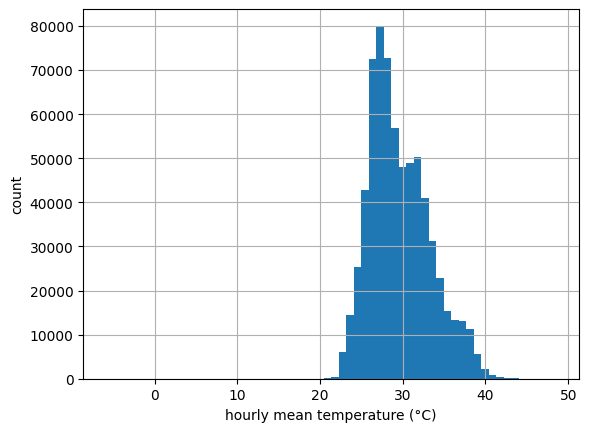

In [40]:
import matplotlib.pyplot as plt
plt.figure()
d['temp'].hist(bins=60)
plt.xlabel('hourly mean temperature (°C)'); plt.ylabel('count')
plt.savefig(f'{BASE}/results/A_fig1_temp_hist.png', dpi=200, bbox_inches='tight')
plt.show()

## 4) 품질 정리 (보고서 '데이터 품질' 섹션 근거)
- **이상치 vs 극한 사건 구분** (2주차): 폭염 때 실제로 높은 기온은 지우면 안 됨. 물리적으로 불가능한 값, 주변 센서와 따로 노는 센서(고장·직사광선)만 제거
- 제거 기준과 제거한 개수 꼭 기록!

In [41]:
d = d[~d['sensor_id'].isin(['OC3CL200010', 'OC3CL200011', 'OC3CL200061', 'OC3CL200065'])]   # 서울대공원(과천) 제외

N_HOURS = 672                      # 8/3~8/30 전체 시간 수
n0, s0 = len(d), d['sensor_id'].nunique()

# 1) 기온 빈 값 제거
d = d.dropna(subset=['temp'])

# 2) 물리적으로 불가능한 값만 제거 (8월 서울 1시간 평균 기준). 폭염 고온은 지우지 않음
bad = (d['temp'] < 15) | (d['temp'] > 50)
print('불가능한 값 제거:', bad.sum(), '행')
d = d[~bad]

# 3) 기간의 70% 이상(470시간 이상) 측정된 센서만 남김
cnt = d.groupby('sensor_id').size()
good = cnt[cnt >= 0.7 * N_HOURS].index
d = d[d['sensor_id'].isin(good)]

print(f'센서: {s0} → {d.sensor_id.nunique()}개 (제거 {s0 - d.sensor_id.nunique()}개)')
print(f'행: {n0} → {len(d)}')
print('42℃ 초과 행(남겨 둠):', (d['temp'] > 42).sum())

불가능한 값 제거: 3 행
센서: 1164 → 963개 (제거 201개)
행: 780240 → 642071
42℃ 초과 행(남겨 둠): 235


## 5) 열섬 강도 = 센서 기온 − 같은 시각 서울 전체 중앙값

In [42]:
d['uhi'] = d['temp'] - d.groupby('time')['temp'].transform('median')
d['hour'] = d['time'].dt.hour
DAY_HOURS = [13, 14, 15, 16]      # TODO: 팀 합의
NIGHT_HOURS = [0, 1, 2, 3, 4, 5]  # TODO: 팀 합의
uhi_day = d[d.hour.isin(DAY_HOURS)].groupby('sensor_id')['uhi'].mean().rename('uhi_day')
uhi_night = d[d.hour.isin(NIGHT_HOURS)].groupby('sensor_id')['uhi'].mean().rename('uhi_night')
lab = pd.concat([uhi_day, uhi_night], axis=1).reset_index()
lab.describe()

,uhi_day,uhi_night
count,963.000000,963.000000
mean,0.013500,-0.108008
std,0.660420,0.726947
min,-3.114015,-2.711997
25%,-0.332028,-0.475646
50%,-0.002408,-0.007830
75%,0.362971,0.350503
max,2.977949,3.611217


## 6) 위치(위경도·구) 붙이고 저장

In [43]:
xl = glob.glob(f'{BASE}/data_raw/sdot/*.xlsx')
print(xl)
loc = pd.read_excel(xl[0], header=0)                   # 첫 줄은 제목이라 둘째 줄을 열 이름으로
loc.columns = loc.columns.astype(str).str.replace(' ', '')
print(loc.columns.tolist())

sid_col = [c for c in loc.columns if '시리얼' in c][0]   # '모델시리얼(*)'
loc = loc.rename(columns={sid_col: 'sensor_id', '위도': 'lat', '경도': 'lon'})
loc['sensor_id'] = loc['sensor_id'].astype(str).str.strip()
loc['gu'] = loc['주소'].astype(str).str.split().str[1]  # '서울특별시 종로구 ...' → '종로구'
print('구가 아닌 주소(제외):', loc.loc[~loc['gu'].str.endswith('구', na=False), '주소'].tolist())
loc = loc[loc['gu'].str.endswith('구', na=False)][['sensor_id', 'gu', 'lat', 'lon']]

labels = loc.merge(lab, on='sensor_id', how='inner')
missing = sorted(set(lab['sensor_id']) - set(labels['sensor_id']))
print(f'열섬 계산된 센서 {len(lab)}개 → 위치까지 붙은 센서 {len(labels)}개 / 위치 못 찾은 센서 {len(missing)}개:', missing[:10])
print('구 개수:', labels['gu'].nunique()); print(labels['gu'].value_counts().tail(5))
labels.to_csv(f'{DATA}/labels.csv', index=False)

['/content/drive/MyDrive/AICEE_project/data_raw/sdot/서울시 도시데이터 센서(S-DoT) 환경정보 설치 위치정보.xlsx']
['No', '모델시리얼(*)', '주소', '좌표구분코드', '위도', '경도', '변경전시리얼', '변경전시리얼(데이터상표기)']
구가 아닌 주소(제외): ['서울대공원', '서울대공원', '서울대공원', '서울대공원']
열섬 계산된 센서 963개 → 위치까지 붙은 센서 963개 / 위치 못 찾은 센서 0개: []
구 개수: 25
gu
동대문구    25
서대문구    25
용산구     24
성북구     22
금천구     22
Name: count, dtype: int64


## 7) 좌표 오류 센서 확인·제외·저장
S-DoT 설치 위치 파일에 주소와 맞지 않는 좌표가 있어 확인하고 제외한다. 원본 파일은 수정하지 않고 코드에서만 처리한다.

**1) 확인** 서울 범위(위도 37.4-37.7, 경도 126.7-127.2) 밖 좌표와, 다른 센서와 좌표가 똑같은 센서를 찾는다.
- OC3KL240004(은평구 녹번동): 위도 37.06으로 서울 밖
- OC3DL220021(성동구 금호동 3가): 관악구 신림동 센서(V02Q2300002)와 좌표가 같음
- OC3DL220020(금호동 4가)도 같은 오류지만 기온 품질 기준에서 이미 제외됨

**2) 제외** 좌표가 틀리면 300m 토지피복 계산이 잘못되므로 위 3개를 뺀다. 963개 → 961개 (정준 님 토지피복 파일과 같은 기준)

**3) 저장** 961개로 labels.csv를 덮어쓰고, 다시 읽어 센서 수를 확인한다.

In [44]:
# 좌표 오류 확인 (빼기 전에 실행)
lat_col = [c for c in labels.columns if 'lat' in c.lower() or '위도' in c][0]
lon_col = [c for c in labels.columns if 'lon' in c.lower() or '경도' in c][0]
pts = labels.drop_duplicates('sensor_id')

# 검사 1: 서울 범위 밖 좌표 (위도 37.4~37.7, 경도 126.7~127.2)
out = pts[~pts[lat_col].between(37.4, 37.7) | ~pts[lon_col].between(126.7, 127.2)]
print('서울 밖 좌표:')
print(out[['sensor_id', lat_col, lon_col]])

# 검사 2: 좌표가 다른 센서와 똑같은 센서
dup = pts[pts.duplicated([lat_col, lon_col], keep=False)].sort_values(lat_col)
print('\n좌표가 겹치는 센서:')
print(dup[['sensor_id', lat_col, lon_col]])

서울 밖 좌표:
       sensor_id       lat         lon
952  OC3KL240004  37.06195  126.921107

좌표가 겹치는 센서:
       sensor_id        lat         lon
956  V02Q2300002  37.470887  126.939107
957  OC3DL220021  37.470887  126.939107


### 좌표 오류 3개 제외 (963 → 961)
위에서 확인한 좌표 오류 센서 3개를 labels에서 뺀다. OC3DL220020은 품질 기준에서 이미 빠져 있어 실제로는 2개가 빠짐. 원본 파일은 수정하지 않음

In [45]:
bad_coord = ['OC3KL240004', 'OC3DL220020', 'OC3DL220021']  # 위치파일 좌표 오류 3개

print('제외 전 센서 수:', labels['sensor_id'].nunique())
for s in bad_coord:
    print(s, '→', '있음' if s in set(labels['sensor_id']) else '이미 없음')

labels = labels[~labels['sensor_id'].isin(bad_coord)].reset_index(drop=True)
print('제외 후 센서 수:', labels['sensor_id'].nunique())   # 961이면 정상

제외 전 센서 수: 963
OC3KL240004 → 있음
OC3DL220020 → 이미 없음
OC3DL220021 → 있음
제외 후 센서 수: 961


### labels.csv 다시 저장
961개로 labels.csv를 덮어쓰고, 다시 읽어 센서 수를 확인

In [46]:
save_path = f'{DATA}/labels.csv'
labels.to_csv(save_path, index=False, encoding='utf-8-sig')
check = pd.read_csv(save_path)
print('저장된 센서 수:', check['sensor_id'].nunique())   # 961이면 완료

저장된 센서 수: 961


### 제외 후 통계 확인
구별 최소 22개, 열섬 강도 표준편차·범위는 963개일 때와 같음 → 제외 영향 거의 없음

In [47]:
print(labels['gu'].value_counts().min())
print(labels[['uhi_day','uhi_night']].describe())

22
          uhi_day   uhi_night
count  961.000000  961.000000
mean     0.013598   -0.106554
std      0.661104    0.727003
min     -3.114015   -2.711997
25%     -0.333077   -0.474497
50%     -0.002408   -0.006045
75%      0.363663    0.352884
max      2.977949    3.611217


### 42℃ 초과 센서 vs 모델1 낮 오차 상위 센서
42℃를 넘은 기록이 있는 센서(67개) 중 5개가 모델1 낮 오차 상위 10개와 겹침(V02Q1940796, 817, 944, 843, 643) → 직사광선·인공 열원으로 센서가 달궈졌을 가능성

In [48]:
import pandas as pd
day_top = ['V02Q1940817','V02Q1940844','V02Q1940676','V02Q1940397','V02Q1940796',
           'V02Q1940643','V02Q1940773','V02Q1940710','V02Q1940944','V02Q1940843']
# 01번에서 시간별 기온이 들어 있는 표 찾기
hourly = [v for v in globals().values() if isinstance(v, pd.DataFrame)
          and {'sensor_id','temp'} <= set(v.columns) and len(v) > 100000][0]
hot = hourly[hourly['temp'] > 42].groupby('sensor_id').size().sort_values(ascending=False)
print('42℃ 넘은 센서 수:', len(hot))
print(hot.head(15))
print('\n낮 오차 상위 10개 중 42℃ 넘은 센서:')
print(hot[hot.index.isin(day_top)])

42℃ 넘은 센서 수: 67
sensor_id
V02Q1940796    22
V02Q1940247    18
V02Q1940817    13
V02Q1940944    10
V02Q1940825    10
V02Q1940843     9
V02Q1940753     8
V02Q1940880     8
V02Q1941013     8
V02Q1940307     8
OC3CL200319     8
V02Q1940798     7
V02Q1940643     7
V02Q1940882     6
V02Q1940848     5
dtype: int64

낮 오차 상위 10개 중 42℃ 넘은 센서:
sensor_id
V02Q1940796    22
V02Q1940817    13
V02Q1940944    10
V02Q1940843     9
V02Q1940643     7
dtype: int64


# 01_labels_A 보고서용 메모 (예슬)
보고서 '데이터(기온)·품질 문제' 섹션 재료

## 데이터
- 출처: 서울 열린데이터광장 '스마트서울 도시데이터 센서(S-DoT) 환경정보(실시간)' 주간 CSV 5개 (08.03–08.30 4개 + 다음 주 08.31–09.06 1개)
- 사용 열: 시리얼(→ sensor_id), 센서 시간(→ time), 평균기온(→ temp, 1시간 평균), 데이터구분번호(DATA_NO)
- 파일 인코딩 cp949 (utf-8로 읽으면 에러)
- 분석 기간: 2026-08-03 00시 – 08-30 23시, 672시간, 센서 1,168대
- 측정값 782,791개 = 가능한 값(1,168 × 672 = 784,896)의 99.7%
- 시간대: 센서시간은 한국 시간(데이터수집시간과 약 15초 차이) → 낮 13–16시, 밤 0–5시 그대로 사용
- 한계: 서울시 데이터 안내에는 '1시간 단위 최소, 최대, 평균값'이라고만 되어 있어, 센서시간 13:07 값이 12–13시 평균인지 13–14시 평균인지는 명시되지 않음 → 정시로 내림(13:07 → 13시)해 사용. 낮·밤 구간이 4–6시간이라 1시간 어긋나도 영향은 작을 것으로 봄

## 데이터 품질 문제와 처리
1. 시간 표기 형식 혼재: `_00:07:00`과 `_23-00-00` 두 형식 → 하나로 통일 후 정시 단위로 맞춤
2. 지연 일괄 전송: 약 300대 센서는 전날 하루치를 다음 날 새벽에 한꺼번에 전송. 주간 파일이 수집일 기준이라 8/2 자료가 섞이고 8/30 자료는 다음 주 파일에 있음 → 다음 주 파일까지 받아 센서시간 기준으로 기간을 자름
3. DATA_NO: 같은 센서·시각에 1(실시간)과 2(보정)가 있으면 2가 최종값. 이번 자료는 전부 1이라 중복 없음 → 한계: 보정값 없이 실시간 수집값만 사용
4. EDA: 기온 결측 약 13.7%. 1시간 평균 기온은 대부분 22–42℃, 밤(약 27℃)·낮(약 32℃) 두 봉우리 (A_fig1_temp_hist.png)
5. 서울대공원 센서 4대 제외: 서울시 운영 시설이지만 행정구역상 경기도 과천이라 자치구 분할에 포함 불가. 중앙값 계산 전에 제외
6. 기온이 기간 내내 없는 센서 48개: 소음은 73% 찍혀 센서는 동작했으나 온습도 부품이 꺼진 것으로 보임 → 제거
7. 기간의 70%(470시간) 미만 측정 센서 제거 (일부 시간대만 측정되면 평균이 치우침)
8. 물리적으로 불가능한 값(15℃ 미만, 50℃ 초과) 제거: 3행, 모두 OC3DL230027 (최저 −5.9℃, 고장)
9. 42℃ 초과 235행은 남김: 주로 V02Q 센서 몇 개에 집중 → 직사광선으로 달궈진 센서일 가능성, 실패 사례 후보. 폭염 고온은 극한 사건일 수 있어 지우지 않음 (2주차 이상치 vs 극한 사건)
10. 결과: 센서 1,164 → 963개 (201개 제거, 좌표 오류 제거 전), 측정값 780,240 → 642,071개
11. 위치정보 엑셀(2026-03-11 기준, 1,170대, WGS84)에 자치구 열이 없어 주소 두 번째 단어로 구를 만듦
12. 좌표 오류 센서 제외(07번): 위치 파일에서 서울 범위(위도 37.4~37.7, 경도 126.7~127.2) 밖 좌표와, 다른 센서와 좌표가 똑같은 센서를 코드로 검사
    - OC3KL240004(은평구 녹번동): 위도 37.06으로 서울 밖
    - OC3DL220021(성동구 금호동 3가): 관악구 신림동 V02Q2300002와 좌표 동일
    - OC3DL220020(성동구 금호동 4가): 신림동 V02Q2300001과 좌표 동일, 기온 품질 기준에서 이미 제외됨
    - 좌표가 틀리면 300m 토지피복 계산이 잘못되므로 제외 → labels.csv 963 → 961개. 원본 파일은 수정하지 않았고, 토지피복 파일(정준 님)도 같은 3개를 뺌
    - 열섬 강도 기준값(서울 중앙값)은 제외 전에 계산해 2개가 포함됐지만, 963개 중 2개라 영향은 매우 작음(제외 후 통계 변화 없음)
    - 팀원 정준 님이 처음 발견했고, 파일 전체를 검사해 3개로 확정
13. 42℃ 초과 센서 67개 중 5개가 모델1 낮 오차 상위 10개와 겹침(V02Q1940796, 817, 944, 843, 643) → 직사광선·인공 열원 실패 사례 근거

## 최종 labels.csv
- 센서 961개, 25개 구 모두 포함, 구별 최소 22개
- uhi_day: 표준편차 0.66℃, 범위 −3.1℃부터 +3.0℃
- uhi_night: 표준편차 0.73℃, 범위 −2.7℃부터 +3.6℃
- 발견: 동네 간 차이가 밤에 더 큼 (도시 열섬은 밤에 강하다는 설명과 일치). 서울대공원 포함 시 밤 최솟값 −3.18℃ → 가장 시원한 센서가 서울 밖 숲 센서였음

## 생성형 AI 사용 기록
- 도구: Claude
- 목적: 2번(열 이름·시간 형식 통일, 중복 처리, 기간 필터), 4번(제거 기준), 6번(위치정보 결합) 셀 코드 작성, 데이터 이상 원인 진단
- 검증: 날짜별·시간대별 행 수, 센서 수, 수집시간과 센서시간 비교로 직접 확인
- 고친 점: 처음 코드가 `_HH-MM-SS` 형식을 못 읽어 518행 변환 실패 → 형식 통일 추가. '19만 행 중복' 해석이 틀렸음을 센서×시간 계산으로 확인. 엑셀 열 이름 줄 지정 오류(header=1 → 0) 수정